In [1]:
from pathlib import Path

import pandas as pd

in_dir = Path("/Users/user/Main/Work/ul_formatted")
# out_dir = Path.home() / "Downloads/ul_formatted"
# out_dir.mkdir(exist_ok=True)

In [2]:
df = pd.read_csv("/Users/user/Downloads/new database.csv")
df["Date"] = df.Date.str[:10]
df
df.to_excel("/Users/user/Downloads/Income-june-sep-25.xlsx")

In [ ]:
{pd.read_csv(p, sep=";").shape for p in in_dir.glob("*.csv")}

{(13771, 1), (14269, 1), (288708, 1)}

In [ ]:
df_path = in_dir / "ul_ciars_to_001.csv"
df = pd.read_csv(df_path, sep=";")
df = df.rename(columns={"app_inn_main": "inn", "app_ogrn_main": "ogrn"})
df.to_csv(out_dir / df_path.name, sep="\t")

In [8]:
df_path = in_dir / "ul_ciars_to_002.csv"
df = pd.read_csv(df_path, sep=";")
df.to_csv(out_dir / df_path.name, sep="\t")

In [ ]:
df_path = in_dir / "ul_ciars_to_003.xlsx"
df = pd.read_excel(df_path)
df = df.rename(columns={"ClientINN": "inn", "OGRN": "ogrn", "ReportDate": "retro_date"})
df = df[["inn", "ogrn", "retro_date"]]
df.to_csv(out_dir / df_path.with_suffix(".csv").name, sep="\t")
df

,inn,ogrn,retro_date
0,3906084414,1023900991927,2015-04-01
1,3906084414,1023900991927,2015-07-01
2,3906084414,1023900991927,2015-10-01
3,3906084414,1023900991927,2016-01-01
4,3906084414,1023900991927,2016-04-01
...,...,...,...
13766,2626029200,1022601226900,2016-10-01
13767,2626029200,1022601226900,2017-01-01
13768,2626029200,1022601226900,2017-04-01
13769,2626029200,1022601226900,2017-07-01


(170758, 4)


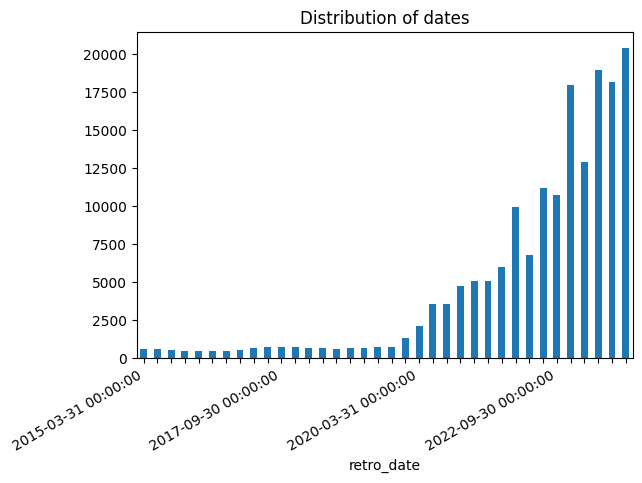

In [ ]:
from matplotlib import pyplot as plt

import matplotlib.dates as mdates

df = pd.concat([pd.read_csv(out_dir / f"ul_ciars_to_00{i}.csv", sep="\t") for i in range(1, 4)])
df["retro_date"] = pd.to_datetime(df["retro_date"])
df = df[df["retro_date"] > pd.Timestamp(year=2000, month=1, day=1)]
df = df[df["retro_date"] < pd.Timestamp(year=2024, month=1, day=1)]
print(df.shape)
df = df.set_index("retro_date")
df = df.resample("QE").size()
fig, ax = plt.subplots()
df.plot.bar(ax=ax)
# ax.set_xticks(df.index[::10])
fig.autofmt_xdate()
# ax.xaxis.set_major_locator(mdates.MonthLocator())
for n, label in enumerate(ax.xaxis.get_ticklabels()):
    if n % 10 != 0:
        label.set_visible(False)
ax.set_title("Distribution of dates")
plt.show()


Модель с тестом на 2022Q3 - компании с датами от 2023Q4 до 2024Q1

Модель с тестом на 2021Q1 - компании с датами от 2022Q2 до 2023Q1
Модель с тестом на 2022Q1 - компании с датами от 2023Q2 до 2024Q1